# Differentiation

**Seong Cho** · ACME Volume 1, Lab 8

**Lab objective:** calculate derivatives symbolically, numerically, and with differentiation software, discuss what settings each is appropriate for, and demonstrate their strengths and weaknesses.

<sub>Lab specification from the *Volume 1* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

> **Note.** This notebook requires [Autograd](https://github.com/HIPS/autograd), which the spec notes is not included in Anaconda (install it with `pip install autograd`). It was run with autograd 1.9.

In [1]:
import sympy as sy
import numpy as np
import matplotlib.pyplot as plt
import autograd.numpy as anp
from autograd import grad
from autograd import elementwise_grad
import time

## Symbolic Differentiation

The derivative of a known mathematical function can be calculated symbolically with SymPy. This is the most precise way to take a derivative, but it is computationally expensive and requires knowing the closed form formula of the function. Use `sy.diff()` to take a symbolic derivative.

In [2]:
x = sy.symbols('x')
sy.diff(x**3 + x, x)            # Differentiate x^3 + x with respect to x.

3*x**2 + 1

## Problem 1: Symbolic derivative

> **Problem 1.** Write a function that defines $f(x) = (\sin(x) + 1)^{\sin(\cos(x))}$ and takes its symbolic derivative with respect to $x$ using SymPy. Lambdify the resulting function so that it can accept NumPy arrays and return the resulting function handle.
>
> To check your function, plot $f$ and its derivative $f'$ over the domain $[-\pi, \pi]$. It may be helpful to move the bottom spine to 0 so you can see where the derivative crosses the $x$-axis.
>
> ```python
> >>> from matplotlib import pyplot as plt
> >>> ax = plt.gca()
> >>> ax.spines["bottom"].set_position("zero")
> ```

In [3]:
def prob1():
    """Return the derivative of (sin(x) + 1)^sin(cos(x)) using SymPy."""
    x = sy.symbols('x')
    f = (sy.sin(x) + 1)**(sy.sin(sy.cos(x)))
    f_p = sy.diff(f, x)
    return sy.lambdify(x, f_p, "numpy")

By logarithmic differentiation, $f'(x) = f(x)\left(-\sin(x)\cos(\cos(x))\log(\sin(x) + 1) + \dfrac{\sin(\cos(x))\cos(x)}{\sin(x) + 1}\right)$, which gives an independent check.

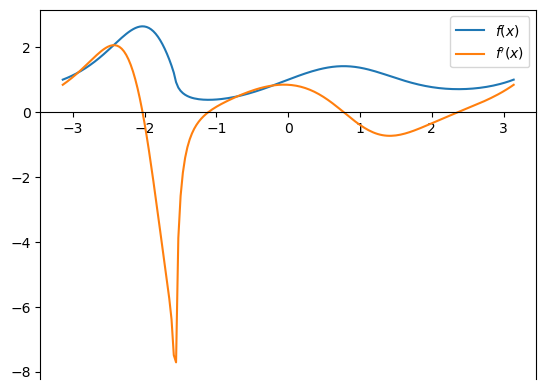

In [4]:
f = lambda x: (np.sin(x) + 1)**np.sin(np.cos(x))
fp = prob1()
domain = np.linspace(-np.pi, np.pi, 200)
by_hand = f(domain) * (-np.sin(domain)*np.cos(np.cos(domain))*np.log(np.sin(domain) + 1)
                       + np.sin(np.cos(domain))*np.cos(domain)/(np.sin(domain) + 1))
assert np.allclose(fp(domain), by_hand)

plt.plot(domain, f(domain), label="$f(x)$")
plt.plot(domain, fp(domain), label="$f'(x)$")
ax = plt.gca()
ax.spines["bottom"].set_position("zero")
plt.legend()
plt.show()

## Numerical Differentiation

One definition for the derivative of a function $f : \mathbb{R} \to \mathbb{R}$ at a point $x_0$ is

$$f'(x_0) = \lim_{h \to 0} \frac{f(x_0 + h) - f(x_0)}{h}.$$

Since this definition relies on $h$ approaching 0, choosing a small, fixed value for $h$ approximates $f'(x_0)$:

$$f'(x_0) \approx \frac{f(x_0 + h) - f(x_0)}{h}. \tag{8.1}$$

This is the *first order forward difference quotient*. Using the points $x_0$ and $x_0 - h$ in place of $x_0 + h$ and $x_0$ gives the *first order backward difference quotient*,

$$f'(x_0) \approx \frac{f(x_0) - f(x_0 - h)}{h}. \tag{8.2}$$

Forward difference quotients use values of $f$ at $x_0$ and points greater than $x_0$; backward quotients use $x_0$ and points less than $x_0$. A *centered* difference quotient uses points on either side of $x_0$, and typically gives a better approximation than the one-sided quotients. Combining (8.1) and (8.2) yields the *second order centered difference quotient*:

$$f'(x_0) = \tfrac{1}{2}f'(x_0) + \tfrac{1}{2}f'(x_0) \approx \frac{f(x_0 + h) - f(x_0)}{2h} + \frac{f(x_0) - f(x_0 - h)}{2h} = \frac{f(x_0 + h) - f(x_0 - h)}{2h}.$$

(The spec's Figure 8.1 shows the secant lines of the forward, centered, and backward quotients next to the tangent line at each point.)

> **Note.** The finite difference quotients in this section all approximate the first derivative of a function. The terms *first order* and *second order* refer to how quickly the approximation converges on the actual value of $f'(x_0)$ as $h$ approaches 0, not to how many derivatives are being taken.
>
> There are finite difference quotients for approximating higher order derivatives, such as $f''$ or $f'''$. For example, the following is a centered difference quotient for the second derivative.
>
> $$f''(x_0) \approx \frac{f(x_0 - h) - 2f(x_0) + f(x_0 + h)}{h^2}$$
>
> This particular quotient is important for finite difference methods that approximate numerical solutions to some partial differential equations.

Other finite difference quotients use more points to approximate the derivative, generally with better convergence properties:

| Type | Order | Formula |
|---|---|---|
| Forward | 1 | $\dfrac{f(x_0+h) - f(x_0)}{h}$ |
| | 2 | $\dfrac{-3f(x_0) + 4f(x_0+h) - f(x_0+2h)}{2h}$ |
| Backward | 1 | $\dfrac{f(x_0) - f(x_0-h)}{h}$ |
| | 2 | $\dfrac{3f(x_0) - 4f(x_0-h) + f(x_0-2h)}{2h}$ |
| Centered | 2 | $\dfrac{f(x_0+h) - f(x_0-h)}{2h}$ |
| | 4 | $\dfrac{f(x_0-2h) - 8f(x_0-h) + 8f(x_0+h) - f(x_0+2h)}{12h}$ |

*Table 8.1: Common finite difference quotients for approximating $f'(x_0)$.*

## Problem 2: Finite difference quotients

> **Problem 2.** Write a function for each of the finite difference quotients listed in Table 8.1. Each function should accept a function handle `f`, an array of points `x`, and a float `h`; each should return an array of the difference quotients evaluated at each point in `x`.
>
> To test your functions, approximate the derivative of $f(x) = (\sin(x) + 1)^{\sin(\cos(x))}$ at each point of a domain over $[-\pi, \pi]$. Plot the results and compare them to the results of Problem 1.

In [5]:
def fdq1(f, x, h=1e-5):
    """Calculate the first order forward difference quotient of f at x."""
    return (f(x + h) - f(x)) / h

def fdq2(f, x, h=1e-5):
    """Calculate the second order forward difference quotient of f at x."""
    return (-3*f(x) + 4*f(x+h) - f(x+2*h))/(2*h)

def bdq1(f, x, h=1e-5):
    """Calculate the first order backward difference quotient of f at x."""
    return (f(x) - f(x-h)) / h

def bdq2(f, x, h=1e-5):
    """Calculate the second order backward difference quotient of f at x."""
    return (3*f(x) - 4*f(x-h) + f(x-2*h))/(2*h)

def cdq2(f, x, h=1e-5):
    """Calculate the second order centered difference quotient of f at x."""
    return (f(x+h) - f(x-h)) / (2*h)

def cdq4(f, x, h=1e-5):
    """Calculate the fourth order centered difference quotient of f at x."""
    return (f(x-2*h) - 8*f(x-h) + 8*f(x+h) - f(x+2*h))/(12*h)

`test1()` plots $f$, the exact $f'$ from Problem 1, and the fourth order centered quotient (red dots) over $[-\pi, \pi]$:

In [6]:
def test1():
    x = sy.symbols('x')
    f = (sy.sin(x) + 1)**(sy.sin(sy.cos(x)))
    f = sy.lambdify(x, f, "numpy")
    fp = prob1()
    domain = np.linspace(-np.pi, np.pi, 200)
    plt.ion()
    plt.plot(domain, f(domain))
    plt.plot(domain, fp(domain))
    plt.scatter(domain, cdq4(f, domain), c='r', s=10, alpha=0.5)
    ax = plt.gca()
    ax.spines["bottom"].set_position("zero")
    plt.show()

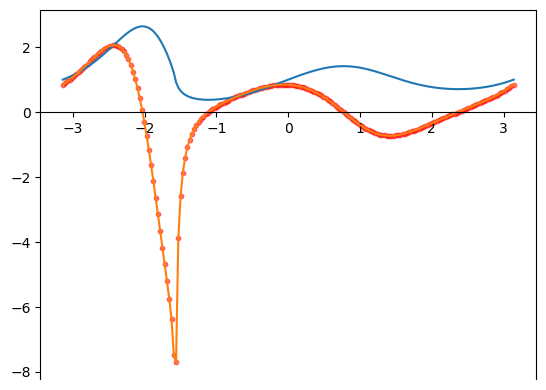

In [7]:
test1()

All six quotients match the exact derivative closely over $[-\pi, \pi]$ at the default $h = 10^{-5}$. Near $x = -\pi/2$, where $\sin(x) + 1 = 0$, the higher derivatives of $f$ blow up, so the order check uses $[0, \pi]$: halving $h$ should divide the error by about $2^p$ for a quotient of order $p$ (the ratio column).

In [8]:
quotients = [("fdq1", fdq1, 1), ("fdq2", fdq2, 2), ("bdq1", bdq1, 1),
             ("bdq2", bdq2, 2), ("cdq2", cdq2, 2), ("cdq4", cdq4, 4)]
smooth = np.linspace(0, np.pi, 100)
print(f"{'':6}{'max error, h=1e-2':>20}{'h=5e-3':>12}{'ratio':>8}   2^order")
for name, q, order in quotients:
    assert np.allclose(q(f, domain), fp(domain), rtol=1e-3, atol=1e-4)
    e1 = np.max(np.abs(q(f, smooth, 1e-2) - fp(smooth)))
    e2 = np.max(np.abs(q(f, smooth, 5e-3) - fp(smooth)))
    print(f"{name:6}{e1:20.2e}{e2:12.2e}{e1/e2:8.2f}   {2**order}")

         max error, h=1e-2      h=5e-3   ratio   2^order
fdq1              9.10e-03    4.55e-03    2.00   2
fdq2              1.36e-04    3.40e-05    4.00   4
bdq1              9.11e-03    4.55e-03    2.00   2
bdq2              1.36e-04    3.40e-05    4.00   4
cdq2              6.79e-05    1.70e-05    4.00   4
cdq4              1.51e-08    9.45e-10   16.00   16


## Convergence of Finite Difference Quotients

Finite difference quotients are typically derived using Taylor's formula, which also shows how the accuracy of the approximation increases as $h \to 0$:

$$f(x_0 + h) = f(x_0) + f'(x_0)h + R_2(h) \implies \frac{f(x_0 + h) - f(x_0)}{h} - f'(x_0) = \frac{R_2(h)}{h}, \tag{8.3}$$

where $R_2(h) = h^2\int_0^1 (1 - t)f''(x_0 + th)\,dt$. Thus the absolute error of the first order forward difference quotient is

$$\left|\frac{R_2(h)}{h}\right| = |h|\left|\int_0^1 (1 - t)f''(x_0 + th)\,dt\right| \le |h|\int_0^1 |1 - t||f''(x_0 + th)|\,dt.$$

If $f''$ is continuous, then for any $\delta > 0$, setting $M = \sup_{x \in (x_0 - \delta, x_0 + \delta)} f''(x)$ guarantees that

$$\left|\frac{R_2(h)}{h}\right| \le |h|\int_0^1 M\,dt = M|h| \in O(h)$$

whenever $|h| < \delta$. That is, the error decreases at the same rate as $h$: if $h$ gets twice as small, so does the error. This is what is meant by a first order approximation. In a second order approximation the absolute error is $O(h^2)$, so if $h$ gets twice as small, the error gets four times smaller.

> **Note.** The notation $O(f(n))$ is commonly used to describe the temporal or spatial complexity of an algorithm. In that context, a $O(n^2)$ algorithm is much worse than a $O(n)$ algorithm. However, when referring to error, a $O(h^2)$ algorithm is better than a $O(h)$ algorithm because it means that the accuracy improves faster as $h$ decreases.

## Problem 3: Error convergence

> **Problem 3.** Write a function that accepts a point $x_0$ at which to compute the derivative of $f(x) = (\sin(x) + 1)^{\sin(\cos(x))}$. Use your function from Problem 1 to compute the exact value of $f'(x_0)$. Then use each your functions from Problem 2 to get an approximate derivative $\tilde{f}'(x_0)$ for $h = 10^{-8}, 10^{-7}, \ldots, 10^{-1}, 1$. Track the absolute error $|f'(x_0) - \tilde{f}'(x_0)|$ for each trial, then plot the absolute error against $h$ on a log-log scale (use `plt.loglog()`).
>
> Instead of using `np.linspace()` to create an array of $h$ values, use `np.logspace()`. This function generates logarithmically spaced values between two powers of 10.
>
> ```python
> >>> import numpy as np
> >>> np.logspace(-3, 0, 4)                   # Get 4 values from 1e-3 to 1e0.
> array([ 0.001, 0.01 , 0.1 , 1. ])
> ```
>
> For $x_0 = 1$, your plot should resemble the following figure. *[The spec's figure: absolute error from about $10^{-12}$ to $1$ against $h$ from $10^{-8}$ to $1$, one line per quotient.]*

In [9]:
np.logspace(-3, 0, 4)                   # Get 4 values from 1e-3 to 1e0.

array([0.001, 0.01 , 0.1  , 1.   ])

In [10]:
def prob3(x0):
    """Let f(x) = (sin(x) + 1)^(sin(cos(x))). Use prob1() to calculate the
    exact value of f'(x0). Then use fdq1(), fdq2(), bdq1(), bdq2(), cdq2(),
    and cdq4() to approximate f'(x0) for h=10^-8, 10^-7, ..., 10^-1, 1.
    Track the absolute error for each trial, then plot the absolute error
    against h on a log-log scale.

    Parameters:
        x0 (float): The point where the derivative is being approximated.
    """
    h = np.logspace(-8, 0, 9)
    x = sy.symbols('x')
    f = (sy.sin(x) + 1)**(sy.sin(sy.cos(x)))
    f = sy.lambdify(x, f, "numpy")
    f_p = prob1()

    o1f = []
    o2f = []
    o1b = []
    o2b = []
    o2c = []
    o4c = []
    for hk in h:
        o1f.append(abs(f_p(x0) - fdq1(f, x0, h=hk)))
        o2f.append(abs(f_p(x0) - fdq2(f, x0, h=hk)))
        o1b.append(abs(f_p(x0) - bdq1(f, x0, h=hk)))
        o2b.append(abs(f_p(x0) - bdq2(f, x0, h=hk)))
        o2c.append(abs(f_p(x0) - cdq2(f, x0, h=hk)))
        o4c.append(abs(f_p(x0) - cdq4(f, x0, h=hk)))

    plt.ion()
    plt.loglog(h, o1f, '-o', label="Order 1 Forward")
    plt.loglog(h, o2f, '-o', label="Order 2 Forward")
    plt.loglog(h, o1b, '-o', label="Order 1 Backward")
    plt.loglog(h, o2b, '-o', label="Order 2 Backward")
    plt.loglog(h, o2c, '-o', label="Order 2 Centered")
    plt.loglog(h, o4c, '-o', label="Order 4 Centered")
    plt.legend()
    plt.xlabel("h")
    plt.ylabel("Absolute Error")
    plt.show()

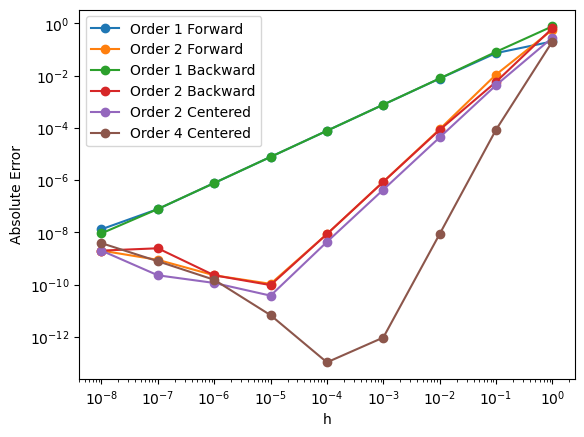

In [11]:
prob3(1)

The lines fall with slopes 1, 2, and 4 as $h$ shrinks from 1, until rounding error takes over for small $h$, as the spec's figure shows.

> **Achtung!** Mathematically, choosing smaller $h$ values results in tighter approximations of $f'(x_0)$. However, Problem 3 shows that when $h$ gets too small, the error stops decreasing. This numerical error is due to the denominator in each finite difference quotient becoming very small. The optimal value of $h$ is usually one that is small, but not too small.

## Problem 4: Radar tracking

> **Problem 4.** The radar stations A and B, separated by the distance $a = 500$ m, track a plane C by recording the angles $\alpha$ and $\beta$ at one-second intervals. Your goal, back at air traffic control, is to determine the speed of the plane.
>
> Let the position of the plane at time $t$ be given by $(x(t), y(t))$. The speed at time $t$ is the magnitude of the velocity vector, $\left\|\frac{d}{dt}(x(t), y(t))\right\| = \sqrt{x'(t)^2 + y'(t)^2}$. The closed forms of the functions $x(t)$ and $y(t)$ are unknown (and may not exist at all), but we can still use numerical methods to estimate $x'(t)$ and $y'(t)$. For example, at $t = 3$, the second order centered difference quotient for $x'(t)$ is
>
> $$x'(3) \approx \frac{x(3 + h) - x(3 - h)}{2h} = \frac{1}{2}(x(4) - x(2)).$$
>
> In this case $h = 1$ since data comes in from the radar stations at 1 second intervals.
>
> Successive readings for $\alpha$ and $\beta$ at integer times $t = 7, 8, \ldots, 14$ are stored in the file `plane.npy`. Each row in the array represents a different reading; the columns are the observation time $t$, the angle $\alpha$ (in degrees), and the angle $\beta$ (also in degrees), in that order. The Cartesian coordinates of the plane can be calculated from the angles $\alpha$ and $\beta$ as follows.
>
> $$x(\alpha, \beta) = a\frac{\tan(\beta)}{\tan(\beta) - \tan(\alpha)} \qquad y(\alpha, \beta) = a\frac{\tan(\beta)\tan(\alpha)}{\tan(\beta) - \tan(\alpha)} \tag{8.4}$$
>
> Load the data, convert $\alpha$ and $\beta$ to radians, then compute the coordinates $x(t)$ and $y(t)$ at each given $t$ using 8.4. Approximate $x'(t)$ and $y'(t)$ using a forward difference quotient for $t = 7$, a backward difference quotient for $t = 14$, and a centered difference quotient for $t = 8, 9, \ldots, 13$ (see Figure 8.1). Return the values of the speed $\sqrt{x'(t)^2 + y'(t)^2}$ at each $t$.¹
>
> (Hint: `np.deg2rad()` will be helpful.)
>
> ¹ This problem originates from *Numerical Methods in Engineering with Python 3* by Jaan Kiusalaas.

The original version computed only the centered quotients, so it returned 6 speeds (for $t = 8, \ldots, 13$). The first order forward quotient at $t = 7$ and backward quotient at $t = 14$ (with $h = 1$) are now added so that all 8 speeds are returned.

In [12]:
def prob4():
    """The radar stations A and B, separated by the distance 500m, track a
    plane C by recording the angles alpha and beta at one-second intervals.
    Your goal, back at air traffic control, is to determine the speed of the
    plane.

    Successive readings for alpha and beta at integer times t=7,8,...,14
    are stored in the file plane.npy. Each row in the array represents a
    different reading; the columns are the observation time t, the angle
    alpha (in degrees), and the angle beta (also in degrees), in that order.
    The Cartesian coordinates of the plane can be calculated from the angles
    alpha and beta as follows.

    x(alpha, beta) = a tan(beta) / (tan(beta) - tan(alpha))
    y(alpha, beta) = (a tan(beta) tan(alpha)) / (tan(beta) - tan(alpha))

    Load the data, convert alpha and beta to radians, then compute the
    coordinates x(t) and y(t) at each given t. Approximate x'(t) and y'(t)
    using a forward difference quotient for t=7, a backward difference
    quotient for t=14, and a centered difference quotient for t=8,9,...,13.
    Return the values of the speed at each t.
    """
    data = np.load('plane.npy')
    a = 500
    t = data[::,0]
    alpha = np.deg2rad(data[::,1])
    beta = np.deg2rad(data[::,2])
    x = a * np.tan(beta) / (np.tan(beta) - np.tan(alpha))
    y = a * np.tan(beta) * np.tan(alpha) / (np.tan(beta) - np.tan(alpha))
    # Changed: added the forward quotient at t=7 and the backward quotient at
    # t=14 (h=1); the original returned only the centered values for t=8,...,13.
    x_p = np.concatenate(([x[1] - x[0]], 1/2 * (x[2:] - x[:-2]), [x[-1] - x[-2]]))
    y_p = np.concatenate(([y[1] - y[0]], 1/2 * (y[2:] - y[:-2]), [y[-1] - y[-2]]))
    return np.sqrt(x_p**2 + y_p**2)

`np.gradient()` with unit spacing uses exactly these quotients (one-sided first order at the ends, centered inside), so it gives an independent check.

In [13]:
speeds = prob4()
data = np.load("plane.npy")
alpha, beta = np.deg2rad(data[:,1]), np.deg2rad(data[:,2])
xt = 500*np.tan(beta) / (np.tan(beta) - np.tan(alpha))
yt = 500*np.tan(beta)*np.tan(alpha) / (np.tan(beta) - np.tan(alpha))
assert np.allclose(speeds, np.sqrt(np.gradient(xt)**2 + np.gradient(yt)**2))

for t, s in zip(data[:,0].astype(int), speeds):
    print(f"t = {t:2d}: speed = {s:.2f} m/s")

t =  7: speed = 46.42 m/s
t =  8: speed = 47.00 m/s
t =  9: speed = 49.00 m/s
t = 10: speed = 50.10 m/s
t = 11: speed = 48.29 m/s
t = 12: speed = 51.56 m/s
t = 13: speed = 53.92 m/s
t = 14: speed = 51.51 m/s


## Numerical Differentiation in Higher Dimensions

Finite difference quotients can also approximate derivatives in higher dimensions. The *Jacobian matrix* of a function $f : \mathbb{R}^n \to \mathbb{R}^m$ at a point $\mathbf{x}_0 \in \mathbb{R}^n$ is the $m \times n$ matrix $J$ whose entries are

$$J_{ij} = \frac{\partial f_i}{\partial x_j}(\mathbf{x}_0).$$

For example, the Jacobian for a function $f : \mathbb{R}^3 \to \mathbb{R}^2$ is

$$J = \begin{bmatrix} \dfrac{\partial f}{\partial x_1} & \dfrac{\partial f}{\partial x_2} & \dfrac{\partial f}{\partial x_3} \end{bmatrix} = \begin{bmatrix} \dfrac{\partial f_1}{\partial x_1} & \dfrac{\partial f_1}{\partial x_2} & \dfrac{\partial f_1}{\partial x_3} \\[2ex] \dfrac{\partial f_2}{\partial x_1} & \dfrac{\partial f_2}{\partial x_2} & \dfrac{\partial f_2}{\partial x_3} \end{bmatrix}, \quad \text{where } f(\mathbf{x}) = \begin{bmatrix} f_1(\mathbf{x}) \\ f_2(\mathbf{x}) \end{bmatrix},\ \mathbf{x} = \begin{bmatrix} x_1 \\ x_2 \\ x_3 \end{bmatrix}.$$

The difference quotients in this case resemble directional derivatives. The first order forward difference quotient for a partial derivative is

$$\frac{\partial f}{\partial x_j}(\mathbf{x}_0) \approx \frac{f(\mathbf{x}_0 + h\mathbf{e}_j) - f(\mathbf{x}_0)}{h},$$

where $\mathbf{e}_j$ is the $j$th standard basis vector. The second order centered difference approximation is

$$\frac{\partial f}{\partial x_j}(\mathbf{x}_0) \approx \frac{f(\mathbf{x}_0 + h\mathbf{e}_j) - f(\mathbf{x}_0 - h\mathbf{e}_j)}{2h}. \tag{8.5}$$

## Problem 5: Jacobian

> **Problem 5.** Write a function that accepts a function $f : \mathbb{R}^n \to \mathbb{R}^m$, a point $\mathbf{x}_0 \in \mathbb{R}^n$, and a float $h$. Approximate the Jacobian matrix of $f$ at $\mathbf{x}$ using the second order centered difference quotient in (8.5).
>
> (Hint: the standard basis vector $\mathbf{e}_j$ is the $j$th column of the $n \times n$ identity matrix $I$.)
>
> To test your function, define a simple function like $f(x, y) = [x^2, x^3 - y]^T$ where the Jacobian is easy to find analytically, then check the results of your function against SymPy or your own scratch work.

In [14]:
def jacobian_cdq2(f, x, h=1e-5):
    """Approximate the Jacobian matrix of f:R^n->R^m at x using the second
    order centered difference quotient.

    Parameters:
        f (function): the multidimensional function to differentiate.
            Accepts a NumPy (n,) ndarray and returns an (m,) ndarray.
            For example, f(x,y) = [x+y, xy**2] could be implemented as follows.
            >>> f = lambda x: np.array([x[0] + x[1], x[0] * x[1]**2])
        x ((n,) ndarray): the point in R^n at which to compute the Jacobian.
        h (float): the step size in the finite difference quotient.

    Returns:
        ((m,n) ndarray) the Jacobian matrix of f at x.
    """
    n = len(x)
    iden = np.eye(n)
    J = np.array([(f(x + h*iden[j])-f(x - h*iden[j]))/(2*h) for j in range(n)])
    return J.T

Checks against SymPy's `Matrix.jacobian()` for the spec's $f(x, y) = [x^2, x^3 - y]^T$ (exact Jacobian $\begin{bmatrix} 2x & 0 \\ 3x^2 & -1 \end{bmatrix}$) and for a non-square $g : \mathbb{R}^3 \to \mathbb{R}^2$:

In [15]:
x1, x2, x3 = sy.symbols('x1 x2 x3')
tests = [(sy.Matrix([x1**2, x1**3 - x2]), [x1, x2]),
         (sy.Matrix([x1*sy.sin(x2) + x3**2, sy.exp(x1*x3) - x2]), [x1, x2, x3])]

np.random.seed(0)
for F, variables in tests:
    f_num = sy.lambdify([variables], list(F), "numpy")       # f(x) for an (n,) array x
    f_vec = lambda x: np.array(f_num(x))
    J_exact = sy.lambdify([variables], F.jacobian(variables), "numpy")
    for _ in range(5):
        x0 = np.random.uniform(-2, 2, len(variables))
        assert np.allclose(jacobian_cdq2(f_vec, x0), J_exact(x0), atol=1e-6)
    print(F.jacobian(variables), "at", np.round(x0, 3))
    print(jacobian_cdq2(f_vec, x0))

Matrix([[2*x1, 0], [3*x1**2, -1]]) at [ 1.855 -0.466]
[[ 3.70930208  0.        ]
 [10.31919146 -1.        ]]
Matrix([[sin(x2), x1*cos(x2), 2*x3], [x3*exp(x1*x3), -1, x1*exp(x1*x3)]]) at [-0.154  1.122 -1.527]
[[ 0.90102064 -0.06683735 -3.05380459]
 [-1.93191172 -1.         -0.19495281]]


## Differentiation Software

Many machine learning algorithms and structures, especially neural networks, rely on the gradient of a cost or objective function. To facilitate their research, several organizations have recently developed Python packages for numerical differentiation. For example, the Harvard Intelligent Probabilistic Systems Group (HIPS) started developing autograd in 2014 (https://github.com/HIPS/autograd) and Google released tangent in 2017 (https://github.com/google/tangent). These tools are incredibly robust: they can differentiate functions with NumPy routines,¹ `if` statements, `while` loops, and even recursion. The spec concludes with a brief introduction to Autograd.²

Autograd's `grad()` accepts a scalar-valued function and returns its gradient as a function that accepts the same parameters as the original. To support most of the NumPy features, Autograd comes with its own thinly-wrapped version of NumPy, `autograd.numpy`, imported as `anp` to avoid confusion.

<sub>¹ See https://github.com/HIPS/autograd/blob/master/docs/tutorial.md for which features Autograd supports. ² Autograd is not included in Anaconda; install it with `pip install autograd`.</sub>

In [16]:
g = lambda x: anp.exp(anp.sin(anp.cos(x)))
dg = grad(g)                    # dg() is a callable function.
dg(1.)                          # Use floats as input, not ints.

np.float64(-1.2069777039799139)

Functions that `grad()` produces do not support array broadcasting, meaning they do not accept arrays as input. Autograd's `elementwise_grad()` returns functions that can accept arrays, like using `"numpy"` as an argument in SymPy's `sy.lambdify()`.

The spec creates the points with `dtype=anp.float`. That alias of the built-in `float` was removed in NumPy 1.24, so `float` is used here.

In [17]:
pts = anp.array([1, 2, 3], dtype=float)
dg = elementwise_grad(g)        # Calculate g'(x) with array support.
dg(pts)                         # Evaluate g'(x) at each of the points.

array([-1.2069777 , -0.55514144, -0.03356146])

SymPy would have no trouble differentiating $g(x)$ in these examples. However, Autograd can also differentiate Python functions that look nothing like traditional mathematical functions. For example, the following code computes the Taylor series of $e^x$ with a loop.

In [18]:
from sympy import factorial

def taylor_exp(x, tol=.0001):
    """Compute the Taylor series of e^x with terms greater than tol."""
    result, i, term = 0, 0, x
    while anp.abs(term) > tol:
        term = x**i / int(factorial(i))
        result, i = result + term, i + 1
    return result

d_exp = grad(taylor_exp)
print(d_exp(2., .1), d_exp(2., .0001))

7.266666666666667 7.388994708994709


## Problem 6: Chebyshev polynomials

> **Problem 6.** The Chebyshev Polynomials are recursively defined as follows.
>
> $$T_0(x) = 1 \qquad T_1(x) = x \qquad T_n(x) = 2xT_{n-1}(x) - T_{n-2}(x)$$
>
> Write a function that accepts an array $x$ and an integer $n$ and recursively computes $T_n(x)$. Use Autograd and your first function to create a function for $T_n'(x)$. Use this last function to plot each $T_n'(x)$ over the domain $[-1, 1]$ for $n = 0, 1, 2, 3, 4$.
>
> (Hint: Use `anp.ones_like(x)` to handle the case when $n = 0$.)

In [19]:
def cheb_poly(x, n):
    """Compute the nth Chebyshev polynomial at x.

    Parameters:
        x (autograd.ndarray): the points to evaluate T_n(x) at.
        n (int): The degree of the polynomial.
    """
    if n == 0:
        return anp.ones_like(x)

    elif n == 1:
        return x

    else:
        return 2*x*cheb_poly(x, n-1) - cheb_poly(x, n-2)


def prob6():
    """Use Autograd and cheb_poly() to create a function for the derivative
    of the Chebyshev polynomials, and use that function to plot the derivatives
    over the domain [-1,1] for n=0,1,2,3,4.
    """
    domain = np.linspace(-1,1,100)
    T_p = elementwise_grad(cheb_poly)
    plt.ion()

    plt.plot(domain, T_p(domain, 0), label="n = 0")
    plt.plot(domain, T_p(domain, 1), label="n = 1")
    plt.plot(domain, T_p(domain, 2), label="n = 2")
    plt.plot(domain, T_p(domain, 3), label="n = 3")
    plt.plot(domain, T_p(domain, 4), label="n = 4")
    plt.legend()
    plt.show()

Checks against NumPy's Chebyshev module: `chebval()` evaluates $T_n$ and `chebder()` differentiates it.

In [20]:
from numpy.polynomial import chebyshev as C

domain = np.linspace(-1, 1, 100)
T_p = elementwise_grad(cheb_poly)
for n in range(1, 8):
    e_n = np.eye(n + 1)[n]                      # Coefficients of T_n in the Chebyshev basis.
    assert np.allclose(cheb_poly(domain, n), C.chebval(domain, e_n))
    assert np.allclose(T_p(domain, n), C.chebval(domain, C.chebder(e_n)))
print("cheb_poly() and its Autograd derivative match NumPy for n = 1, ..., 7.")

cheb_poly() and its Autograd derivative match NumPy for n = 1, ..., 7.


$T_0 = 1$ is constant, so Autograd warns that the output seems independent of the input (and returns the zero derivative). That expected warning is silenced here.

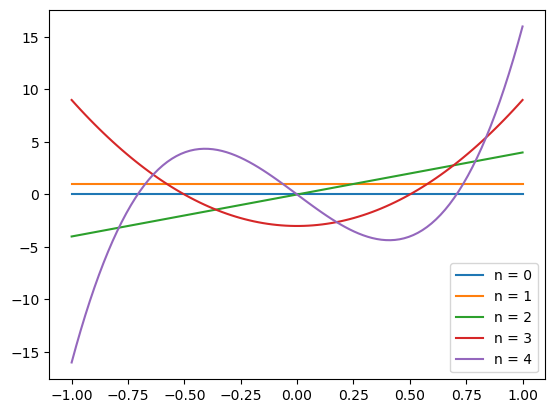

In [21]:
import warnings
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", "Output seems independent of input")
    prob6()

## Problem 7: SymPy vs. difference quotients vs. Autograd

> **Problem 7.** Let $f(x) = (\sin(x) + 1)^{\sin(\cos(x))}$ as in Problems 1 and 3. Write a function that accepts an integer $N$ and performs the following experiment $N$ times.
>
> 1. Choose a random value $x_0$.
> 2. Use your function from Problem 1 to calculate the "exact" value of $f'(x_0)$. Time how long the entire process takes, including calling your function (each iteration).
> 3. Time how long it takes to get an approximation $\tilde{f}'(x_0)$ of $f'(x_0)$ using the fourth-order centered difference quotient from Problem 3. Record the absolute error $|f'(x_0) - \tilde{f}'(x_0)|$ of the approximation.
> 4. Time how long it takes to get an approximation $\bar{f}'(x_0)$ of $f'(x_0)$ using Autograd (calling `grad()` every time). Record the absolute error $|f'(x_0) - \bar{f}'(x_0)|$ of the approximation.
>
> Plot the computation times versus the absolute errors on a log-log plot with different colors for SymPy, the difference quotient, and Autograd. For SymPy, assume an absolute error of `1e-18` (since only positive values can be shown on a log plot).
>
> For $N = 200$, your plot should resemble the following figure. Note that SymPy has the least error but the most computation time, and that the difference quotient takes the least amount of time but has the most error. *[The spec's figure: absolute errors from $10^{-18}$ to $10^{-11}$ against computation times of about $5 \times 10^{-5}$ seconds for the difference quotient, $3 \times 10^{-4}$ for Autograd, and $6 \times 10^{-3}$ for SymPy.]*

The original fixed the axes to `plt.xlim(2e-5, 5e-2)` and `plt.ylim(5e-19, 1e-10)`. On this machine the difference quotient takes about $10^{-5}$ seconds or less, which puts it entirely outside those limits (and the $y$ limit clipped a few of its larger errors). The two lines are commented out so the axes scale to the data. Autograd's error is sometimes exactly 0, and those points can't appear on a log scale.

In [22]:
def prob7(N=200):
    """Let f(x) = (sin(x) + 1)^sin(cos(x)). Perform the following experiment N
    times:

        1. Choose a random value x0.
        2. Use prob1() to calculate the “exact” value of f′(x0). Time how long
            the entire process takes, including calling prob1() (each
            iteration).
        3. Time how long it takes to get an approximation of f'(x0) using
            cdq4(). Record the absolute error of the approximation.
        4. Time how long it takes to get an approximation of f'(x0) using
            Autograd (calling grad() every time). Record the absolute error of
            the approximation.

    Plot the computation times versus the absolute errors on a log-log plot
    with different colors for SymPy, the difference quotient, and Autograd.
    For SymPy, assume an absolute error of 1e-18.
    """
    f = lambda x: (anp.sin(x) + 1)**(anp.sin(anp.cos(x)))
    T1 = []
    T2 = []
    T3 = []
    E2 = []
    E3 = []
    for i in range(N):
        x = np.random.random() * 10
        t1 = time.time()
        p_sy = prob1()(x)
        t2 = time.time()
        e2 = abs(p_sy - cdq4(f, x))
        t3 = time.time()
        e3 = abs(p_sy - grad(f)(x))
        t4 = time.time()

        T1.append(t2-t1)
        T2.append(t3-t2)
        T3.append(t4-t3)
        E2.append(e2)
        E3.append(e3)

    E1 = np.ones_like(T1) * 1e-18
    plt.ion()
    plt.scatter(T1, E1, alpha=0.3, label="Sympy")
    plt.scatter(T2, E2, alpha=0.3, label="Difference Quotients")
    plt.scatter(T3, E3, alpha=0.3, label="Autograd")
    plt.xscale("log")
    plt.yscale("log")
    # Changed: the fixed limits below cut the difference quotient points
    # (mostly under 2e-5 seconds here) out of the plot; let the axes autoscale.
    # plt.xlim(2e-5, 5e-2)
    # plt.ylim(5e-19, 1e-10)
    plt.legend()
    plt.show()

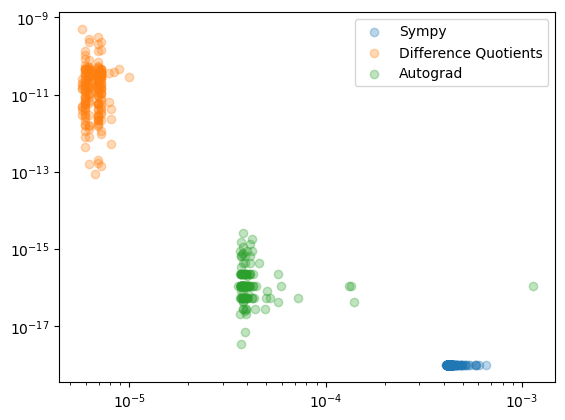

In [23]:
np.random.seed(0)
prob7(200)

Timings depend on the machine, but the ordering matches the spec: SymPy is exact but slowest, the difference quotient is fastest but least accurate, and Autograd is in between on time while matching SymPy to within a few times $10^{-15}$.

## Additional Material

### More Autograd

For scalar-valued functions with multiple inputs, the parameter `argnum` specifies the variable that the derivative is computed with respect to. Providing a list for `argnum` gives several outputs.

In [24]:
f = lambda x,y: 3*x*y + 2*y - x

# Take the derivative of f with respect to the first variable, x.
dfdx = grad(f, argnum=0)        # Should be dfdx(x,y) = 3y - 1,
print(dfdx(5., 1.))             # so dfdx(5,1) = 3 - 1 = 2.

# Take the gradient with respect to the second variable, y.
dfdy = grad(f, argnum=1)        # Should be dfdy(x,y) = 3x + 2,
print(dfdy(5., 1.))             # so dfdy(5,1) = 15 + 2 = 17.

# Get the full gradient.
grad_f = grad(f, argnum=[0,1])
anp.array(grad_f(5., 1.))

2.0
17.0


array([ 2., 17.])

Finally, Autograd's `jacobian()` can differentiate vector-valued functions.

In [25]:
from autograd import jacobian
f = lambda x: anp.array([x[0]**2, x[0]+x[1]])
f_jac = jacobian(f)
f_jac(anp.array([1., 1.]))

array([[2., 0.],
       [1., 1.]])

### Google Tangent

Google's `tangent` package is similar to Autograd, both in purpose and syntax. However, Tangent differentiates code ahead of time, while Autograd waits until the last second to actually do any calculations. Tangent also tends to be slightly faster than Autograd. (Tangent isn't installed here, so the spec's example is shown as written.)

```python
>>> import tangent                  # Install with 'pip install tangent'.
>>> def f(x):                       # Tangent does not support lambda functions,
...     return x**2 - x + 3
...
>>> df = tangent.grad(f)
>>> df(10)                          # ...but the functions do accept integers.
19.0
```